In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt
import sys
import powerlaw
import matplotlib.lines as mlines

%pip install powerlaw


from cycler import cycler

plt.rcParams.update({
    "font.family": "STIXGeneral",
    "mathtext.fontset": "stix",
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "legend.fontsize": 11,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

colors = plt.get_cmap("viridis")(np.linspace(0, 1, 10))
plt.rcParams["axes.prop_cycle"] = cycler(color=colors)

Note: you may need to restart the kernel to use updated packages.


In [3]:
def create_network(N, K):
    p_connect = K / N #probability that two elements are connected

    neighbours = [[] for _ in range(N)] #outgoing edges

    for i in range(N):
        for j in range(i+1, N): 
            if random.random() < p_connect:
                neighbours[i].append(j)
                neighbours[j].append(i)
    return neighbours

In [5]:
def init_p_values(neighbours, sigma, K):
    p_max = (2 * sigma / K) #in the paper it's 2*sigma/K

    p_values = [[] for _ in range(len(neighbours))]
    edge_values = {}

    for i, nb in enumerate(neighbours):
        for j in nb:
            edge = tuple(sorted((i,j)))

            if edge not in edge_values:
                edge_values[edge] = random.uniform (0, p_max)

            p_values[i].append(edge_values[edge])

    return p_values

In [7]:
def init_states(N, initial_active):
    states = [0] * N
    for i in random.sample(range(N), initial_active):
        states[i] = 1
    return states

In [8]:
def external_stimulation(N, r):
    dt=1
    p_ext = 1 - np.exp(-r * dt) #in the paper they call it lambda
    stimulated = []
    for i in range(N):
        if random.random() < p_ext:
            stimulated.append(i)
    return stimulated
    
    
#at every time step, every node can be activated by an external stimulus, probability modelled by a Poisson process


[21, 14, 10, 11, 9, 11, 7, 12, 15, 9, 15, 10, 9, 10, 5, 10, 11, 5, 9, 10]


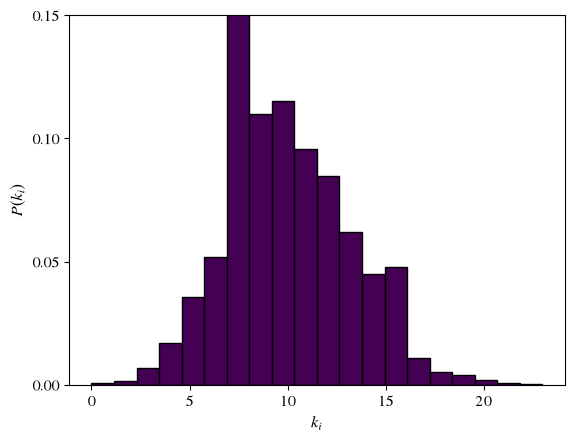

average degree K: 9.9814
[7, 7, 14, 11, 8, 10, 10, 4, 10, 11, 12, 13, 7, 5, 11, 11, 7, 11, 7, 13]


In [ ]:
#inset plot of figure 1A to check if K is correct

neighbours = create_network(10000, 10)

degrees = [len(nb) for nb in neighbours]
print(degrees[:20])

plt.hist(degrees, bins=20, edgecolor='black', density=True)
plt.xlabel(r"$k_i$")
plt.ylabel(r"$P(k_i)$")
plt.yticks(np.arange(0, 0.16, 0.05))
plt.ylim(0, 0.15)
plt.savefig("mein_plot.pdf") 
plt.show()


avg_degree = np.mean([len(nbs) for nbs in neighbours])
print("average degree K:", avg_degree)



neighbours = create_network(10000, 10)

degrees = [len(nb) for nb in neighbours]
print(degrees[:20])


In [9]:
def update_states(prev_states, neighbours, p_values, num_states, N, r=0): #r=0 means no external stimulation
    N = len(prev_states)
    new_states = prev_states.copy()
    
    for i in range(N):
        if prev_states[i] >= 1: #resting states are not affected
            if prev_states[i] < num_states - 1:
                new_states[i] += 1
            else:
                new_states[i] = 0 #when n-1 is reached -> back to resting

    #resting (still missing: excitement through external stimuli, but for plot 1B not required)
    for i in range(N):
        if prev_states[i] == 1:
            for idx, j in enumerate(neighbours[i]):
                if prev_states[j] == 0: #can only be excited when in resting state
                    if random.random() < p_values[i][idx]:
                        new_states[j] = 1

    #external stimulation
    stimulated = external_stimulation(N, r) #rate r is proportional to stimulus level S
    for i in stimulated:
        if new_states[i] == 0: #can only be excited when still in resting state
            new_states[i] = 1
                
    return new_states

In [10]:
def run_simulation(N, K, num_states, initial_active, sigma, timesteps):
    neighbours = create_network(N, K)
    p_values = init_p_values(neighbours, sigma, K)
    states = init_states(N, initial_active)

    activity = []

    for t in range(timesteps):
        active_count = sum(1 for s in states if s == 1)
        activity.append(active_count)
        states = update_states(states, neighbours, p_values, num_states, N)

    return np.array(activity)

In [11]:
def plot_activity(activity_dict, N):
    plt.figure(figsize=(10,5))

    # collect sigma values from keys like 'sigma=0.95, run=1'
    import re
    sigma_vals = []
    for key in activity_dict.keys():
        m = re.search(r'sigma=([0-9\.]+)', key)
        if m:
            sigma_vals.append(float(m.group(1)))
    unique_sigmas = sorted(set(sigma_vals))

    # choose a color for each sigma group
    cmap = plt.get_cmap('viridis') #gets already defined color palette with 10 colors
    #color_map = {s: cmap(i % 10) for i, s in enumerate(unique_sigmas)}
    color_map = {
        s: cmap(i / (len(unique_sigmas) - 1))
        for i, s in enumerate(unique_sigmas)
    }

    for label, activity in activity_dict.items():
        m = re.search(r'sigma=([0-9\.]+)', label)
        sigma = float(m.group(1)) if m else None
        color = color_map.get(sigma, 'black')
        density = activity / N
        time = np.arange(len(activity))
        plt.plot(time, density, label=label, color=color, alpha=0.7)

    plt.xlabel("Time (ms)")
    plt.ylabel("Density")
    plt.yscale('log')
    plt.ylim(1e-5, 1e-1)
    #plt.xlim(0, 200)
    plt.grid(True, which='both', alpha=0.7)

    # show a concise legend for sigma groups (one handle per sigma)
    import matplotlib.lines as mlines
    handles = [mlines.Line2D([], [], color=color_map[s], label=f'sigma={s}') for s in unique_sigmas]
    plt.legend(handles=handles)
    plt.savefig("Figure_2.pdf") 
    plt.show()
    


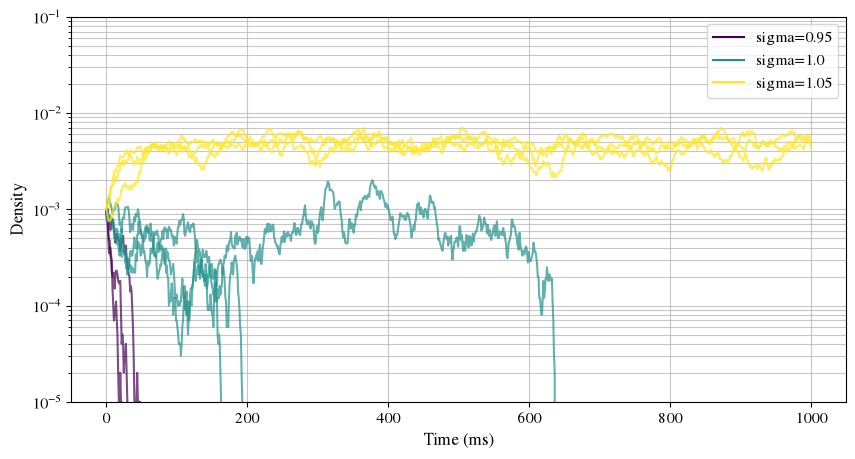

In [18]:
N = 100000 #in the paper they use 10^5
num_states = 10
K = 10
initial_active = 100
sigma_values = [0.95, 1, 1.05] #in the paper they use 0.95, 1 and 1.05
runs_per_sigma = 3
timesteps = 1000

activity_dict = {}

for sigma in sigma_values:
    for run in range(runs_per_sigma):
        activity = run_simulation(N, K, num_states, initial_active, sigma, timesteps)
        key = f"sigma={sigma}, run={run+1}"
        activity_dict[key] = activity

plot_activity(activity_dict, N)

In [12]:
def run_avalanche_simulation(N, K, num_states, sigma, max_steps, num_avalanches):
    neighbours = create_network(N, K)
    p_values = init_p_values(neighbours, sigma, K)

    all_avalanches = []
    censored = 0
    
    for _ in range(num_avalanches):
        states = init_states(N, initial_active=1)
        avalanche_size = 0
        finished = False

        for t in range(max_steps):
            active_count = sum(1 for s in states if s == 1)

            if active_count == 0:
                finished = True
                break

            avalanche_size += active_count
            states = update_states(states, neighbours, p_values, num_states, N)

        if finished:
            all_avalanches.append(avalanche_size)
        else:
            censored += 1

    return all_avalanches, censored

    #important: I could continue adding to activity only until a zero appears (avalanche ends), but for the other plot (density of active nodes) we need the full activity for every timestep

In [13]:
# import re

# def plot_avalanches(avalanche_dict):
#     plt.figure(figsize=(8,6))

#     # collect sigma values
#     sigma_vals = []
#     for key in avalanche_dict.keys():
#         m = re.search(r'sigma=([0-9\.]+)', key)
#         if m:
#             sigma_vals.append(float(m.group(1)))

#     unique_sigmas = sorted(set(sigma_vals))

#     #one color per sigma
#     cmap = plt.get_cmap("viridis")

#     if len(unique_sigmas) == 1:
#         color_map = {unique_sigmas[0]: cmap(0.5)}
#     else:
#         color_map = {
#             s: cmap(i / (len(unique_sigmas) - 1))
#             for i, s in enumerate(unique_sigmas)
#         }

#     for label, sizes in avalanche_dict.items():
#         m = re.search(r'sigma=([0-9\.]+)', label)
#         sigma = float(m.group(1))
#         color = color_map[sigma]

#         sizes = np.array(sizes)
#         sizes = sizes[sizes > 0]

#         bins = np.logspace(np.log10(min(sizes)), np.log10(max(sizes)), 30)
#         hist, edges = np.histogram(sizes, bins=bins, density=True)
#         centers = np.sqrt(edges[:-1] * edges[1:])

#         plt.loglog(centers, hist, 'o', color=color, label=label)

#     plt.xlabel("Avalanche size $S$")
#     plt.ylabel("Probability $P(S)$")
#     plt.grid(True, which="both", alpha=0.3)

#     # Falls du nur eine Legende pro Sigma möchtest:
#     import matplotlib.lines as mlines
#     handles = [
#         mlines.Line2D([], [], color=color_map[s], marker='o',
#                       linestyle='None', label=f'sigma={s}')
#         for s in unique_sigmas
#     ]
#     plt.legend(handles=handles)

#     plt.show()

In [17]:
import re


def plot_avalanches(avalanche_dict):
    plt.figure(figsize=(8,6))

    # Referenzlinie vorbereiten
    ref_centers = None
    ref_hist = None
    all_sizes = []

    # collect sigma values
    sigma_vals = []
    for key in avalanche_dict.keys():
        m = re.search(r'sigma=([0-9\.]+)', key)
        if m:
            sigma_vals.append(float(m.group(1)))

    unique_sigmas = sorted(set(sigma_vals))

    # one color per sigma
    cmap = plt.get_cmap("viridis")

    if len(unique_sigmas) == 1:
        color_map = {unique_sigmas[0]: cmap(0.5)}
    else:
        color_map = {
            s: cmap(i / (len(unique_sigmas) - 1))
            for i, s in enumerate(unique_sigmas)
        }

    for label, sizes in avalanche_dict.items():
        m = re.search(r'sigma=([0-9\.]+)', label)
        sigma = float(m.group(1))
        color = color_map[sigma]

        sizes = np.array(sizes)
        sizes = sizes[sizes > 0]

        all_sizes.append(sizes)

        bins = np.logspace(np.log10(min(sizes)), np.log10(max(sizes)), 30)
        hist, edges = np.histogram(sizes, bins=bins, density=True)
        centers = np.sqrt(edges[:-1] * edges[1:])

        plt.loglog(centers, hist, 'o', color=color)

        # Ersten Datensatz als Referenz speichern
        if ref_centers is None:
            ref_centers = centers
            ref_hist = hist

    # -------- Referenzlinie S^{-3/2} --------
    all_sizes = np.concatenate(all_sizes)

    x_ref = np.logspace(np.log10(min(all_sizes)),
                        np.log10(max(all_sizes)), 200)

    # mittleren Bereich zur Skalierung verwenden
    mask = ((ref_centers > np.percentile(ref_centers, 30)) &
            (ref_centers < np.percentile(ref_centers, 70)))

    scale = np.mean(ref_hist[mask] /
                    (ref_centers[mask]**(-1.5)))

    y_ref = scale * x_ref**(-1.5)

    plt.loglog(x_ref, y_ref, '--', color='black',
               linewidth=2)

    # -------- Layout --------
    plt.xlabel("Avalanche size $S$")
    plt.ylabel("Probability $P(S)$")
    plt.grid(True, which="both", alpha=0.3)

    # Legende
    handles = [
        mlines.Line2D([], [], color=color_map[s], marker='o',
                      linestyle='None', label=f'sigma={s}')
        for s in unique_sigmas
    ]

    handles.append(
        mlines.Line2D([], [], color='black',
                      linestyle='--',
                      label=r'$S^{-3/2}$')
    )

    plt.legend(handles=handles)
    plt.tight_layout()
    plt.savefig("Figure_3.pdf") 
    plt.show()

In [18]:
def powerlaw_fit(avalanche_dict, sigma):
    data = avalanche_dict[f"sigma={sigma}"]

    fit = powerlaw.Fit(data, discrete=True)

    alpha = fit.power_law.alpha
    xmin = fit.power_law.xmin

    R, p = fit.distribution_compare(
        'power_law',
        'truncated_power_law'
    )

    return alpha, xmin, R, p


#alpha, xmin, R, p = powerlaw_fit(avalanche_dict, sigma)

In [19]:
N = 10000
num_states = 10
K = 10
max_steps = 1000

sigma_values = [0.95, 1, 1.05]
num_avalanches = 1000
network_runs = 5

results = {}

for sigma in sigma_values:
    results[sigma] = []

    for run in range(network_runs):

        sizes, censored = run_avalanche_simulation(
            N, K, num_states, sigma,
            max_steps, num_avalanches
        )

        temp_dict = {f"sigma={sigma}": sizes}

        alpha, xmin, R, p = powerlaw_fit(
            temp_dict, sigma
        )

        results[sigma].append({
            "alpha": alpha,
            "xmin": xmin,
            "R": R,
            "p": p,
            "censored": censored
        })

        print(
            f"sigma={sigma}, run={run+1}: "
            f"alpha={alpha:.3f}, "
            f"xmin={xmin}, "
            f"R={R:.2f}, "
            f"p={p:.3g}, "
            f"censored={censored}/{num_avalanches}"
        )


for sigma in sigma_values:

    alphas = [r["alpha"] for r in results[sigma]]
    censored_vals = [r["censored"] for r in results[sigma]]

    print(f"\nSigma = {sigma}")
    print(f"mean alpha = {np.mean(alphas):.3f}")
    print(f"std alpha = {np.std(alphas):.3f}")
    print(f"mean censored = {np.mean(censored_vals):.1f}")

Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 98/98 [00:00<00:00, 360.66it/s]
c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


sigma=0.95, run=1: alpha=1.587, xmin=1.0, R=-19.09, p=6.43e-10, censored=0/1000
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 100/100 [00:00<00:00, 301.75it/s]
c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


sigma=0.95, run=2: alpha=1.593, xmin=1.0, R=-16.69, p=7.6e-09, censored=0/1000
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 107/107 [00:00<00:00, 423.00it/s]
c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')


... (22 outputs left out)

sigma=1.05, run=4: alpha=1.426, xmin=1.0, R=-3.17, p=0.0118, censored=3/1000
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 170/170 [00:00<00:00, 201.89it/s]


sigma=1.05, run=5: alpha=1.436, xmin=1.0, R=-4.08, p=0.00428, censored=0/1000

Sigma = 0.95
mean alpha = 1.598
std alpha = 0.037
mean censored = 0.0

Sigma = 1
mean alpha = 1.514
std alpha = 0.012
mean censored = 0.0

Sigma = 1.05
mean alpha = 1.414
std alpha = 0.016
mean censored = 6.0


c:\Users\Ramona\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\powerlaw\distributions.py:808: UserWarning: Fitted parameters are very close to the edge of parameter ranges for distribution truncated_power_law; consider changing these ranges.
  warnings.warn(f'Fitted parameters are very close to the edge of parameter ranges for distribution {self.name}; consider changing these ranges.')
